
Sample size: 50000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

Sample size: 100000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

Sample size: 300000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

Sample size: 400000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

Sample size: 500000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

Sample size: 600000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

ALL RESULTS
   Sample Size  Corruption (%)  Repetition  Corrupted Observations  \
0        50000               0           1                       0   
1        50000               0           2                    

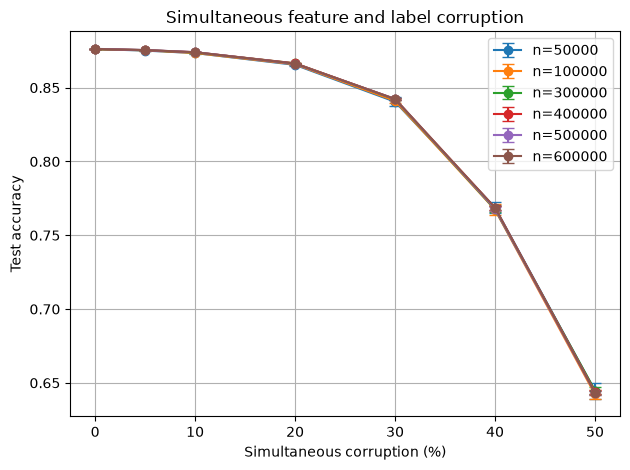

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score


# --------------------------------------------------
# 1. Load dataset
# --------------------------------------------------

df = pd.read_csv("train.csv")

X = df.drop(columns=["id", "satisfaction"]).copy()
y = df["satisfaction"].astype(int)


# --------------------------------------------------
# 2. Feature columns
# --------------------------------------------------

categorical_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]


# Use the same five important features as before
important_features = [
    "Online boarding",
    "Inflight wifi service",
    "Inflight entertainment",
    "Seat comfort",
    "Ease of Online booking"
]


# --------------------------------------------------
# 3. Fixed train-test split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


# --------------------------------------------------
# 4. Build LinearSVC
# --------------------------------------------------

def build_svm():

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LinearSVC(
            C=1.0,
            dual=False,
            max_iter=5000,
            random_state=42
        ))
    ])

    return model


# --------------------------------------------------
# 5. Simultaneous corruption
# --------------------------------------------------

def simultaneous_corruption(
    X_original,
    y_original,
    features,
    rate,
    rng
):

    X_corrupted = X_original.copy()
    y_corrupted = y_original.copy()

    n = len(X_original)

    n_corrupt = int(rate * n)

    # Select one common set of observations
    indices = rng.choice(
        n,
        size=n_corrupt,
        replace=False
    )

    # ----------------------------------------------
    # A. Corrupt labels at these observations
    # ----------------------------------------------

    y_corrupted.iloc[indices] = (
        1 - y_corrupted.iloc[indices]
    )

    # ----------------------------------------------
    # B. Corrupt all five features at the SAME
    #    observations
    # ----------------------------------------------

    for feature in features:

        valid_values = (
            X_original[feature].dropna().unique()
        )

        if len(valid_values) < 2:
            continue

        original_values = X_original.loc[
            indices, feature
        ].to_numpy()

        replacement_values = rng.choice(
            valid_values,
            size=n_corrupt,
            replace=True
        )

        # Ensure replacements differ from originals
        same = replacement_values == original_values

        while np.any(same):

            replacement_values[same] = rng.choice(
                valid_values,
                size=np.sum(same),
                replace=True
            )

            same = replacement_values == original_values

        X_corrupted.loc[
            indices, feature
        ] = replacement_values

    return X_corrupted, y_corrupted, indices


# --------------------------------------------------
# 6. Experimental settings
# --------------------------------------------------

sample_sizes = [
    50000, 100000, 300000, 400000, 500000, 600000
]

corruption_levels = [
    0, 5, 10, 20, 30, 40, 50
]

REPETITIONS = 10

results = []


# Create nested training subsets
sample_rng = np.random.default_rng(123)

permutation = sample_rng.permutation(len(X_train))

X_ordered = X_train.iloc[permutation].reset_index(drop=True)
y_ordered = y_train.iloc[permutation].reset_index(drop=True)


# --------------------------------------------------
# 7. Run experiment
# --------------------------------------------------

for n in sample_sizes:

    print(f"\nSample size: {n}")

    X_subset = X_ordered.iloc[:n].copy()
    y_subset = y_ordered.iloc[:n].copy()

    for rate in corruption_levels:

        print(f"Corruption: {rate}%")

        for rep in range(REPETITIONS):

            rng = np.random.default_rng(
                seed=100000 + n * 100 + rate * 10 + rep
            )

            # Simultaneous corruption on same observations
            X_noisy, y_noisy, indices = (
                simultaneous_corruption(
                    X_subset,
                    y_subset,
                    important_features,
                    rate / 100,
                    rng
                )
            )

            # Train model
            model = build_svm()

            model.fit(X_noisy, y_noisy)

            # Predictions on clean test set
            predictions = model.predict(X_test)

            # Evaluate
            accuracy = accuracy_score(
                y_test, predictions
            )

            f1 = f1_score(
                y_test, predictions
            )

            # Save results
            results.append({

                "Sample Size": n,

                "Corruption (%)": rate,

                "Repetition": rep + 1,

                "Corrupted Observations": len(indices),

                "Test Accuracy": accuracy,

                "Test F1": f1

            })


# --------------------------------------------------
# 8. Results dataframe
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("\nALL RESULTS")
print(results_df.head())

results_df.to_csv(
    "simultaneous_feature_label_corruption.csv",
    index=False
)


# --------------------------------------------------
# 9. Mean and standard deviation
# --------------------------------------------------

summary = results_df.groupby(
    ["Sample Size", "Corruption (%)"]
).agg({

    "Test Accuracy": ["mean", "std"],

    "Test F1": ["mean", "std"]

})

print("\nMEAN AND STANDARD DEVIATION")
print(summary.round(5))

summary.to_csv(
    "simultaneous_corruption_summary.csv"
)


# --------------------------------------------------
# 10. Mean accuracy table
# --------------------------------------------------

mean_table = results_df.pivot_table(
    index="Sample Size",
    columns="Corruption (%)",
    values="Test Accuracy",
    aggfunc="mean"
)

print("\nMEAN ACCURACY TABLE")
print(mean_table.round(5))


# --------------------------------------------------
# 11. Standard deviation table
# --------------------------------------------------

std_table = results_df.pivot_table(
    index="Sample Size",
    columns="Corruption (%)",
    values="Test Accuracy",
    aggfunc="std"
)

print("\nSTANDARD DEVIATION TABLE")
print(std_table.round(5))


# --------------------------------------------------
# 12. Plot accuracy versus corruption
# --------------------------------------------------

for n in sample_sizes:

    subset = results_df[
        results_df["Sample Size"] == n
    ]

    grouped = subset.groupby(
        "Corruption (%)"
    )["Test Accuracy"].agg(["mean", "std"])

    plt.errorbar(
        grouped.index,
        grouped["mean"],
        yerr=grouped["std"],
        marker="o",
        capsize=4,
        label=f"n={n}"
    )

plt.xlabel("Simultaneous corruption (%)")
plt.ylabel("Test accuracy")
plt.title(
    "Simultaneous feature and label corruption"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Numerical features: 17
Categorical features: 4
Total features: 21

Sample size: 100000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

Sample size: 200000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

Sample size: 300000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

Sample size: 400000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

Sample size: 500000
Corruption: 0%
Corruption: 5%
Corruption: 10%
Corruption: 20%
Corruption: 30%
Corruption: 40%
Corruption: 50%

ALL RESULTS
   Sample Size  Corruption (%)  Repetition  Corrupted Observations  \
0       100000               0           1                       0   
1       100000               0           2                       0   
2       100000               0           3              

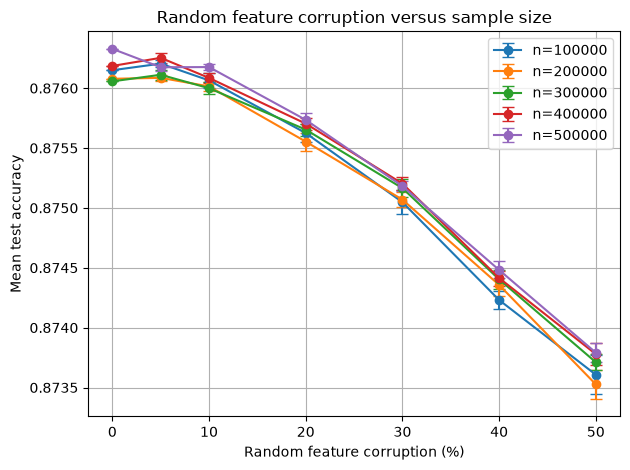


ACCURACY DROP TABLE
Corruption (%)   0        5        10       20       30       40       50
Sample Size                                                              
100000          0.0 -0.00006  0.00009  0.00052  0.00110  0.00192  0.00254
200000          0.0 -0.00001  0.00006  0.00052  0.00101  0.00172  0.00255
300000          0.0 -0.00006  0.00006  0.00040  0.00089  0.00165  0.00235
400000          0.0 -0.00007  0.00010  0.00048  0.00098  0.00177  0.00241
500000          0.0  0.00015  0.00015  0.00059  0.00115  0.00185  0.00254


In [ ]:
#Linear SVM under arbitrary feature corruption


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score


# --------------------------------------------------
# 1. Load dataset
# --------------------------------------------------

df = pd.read_csv("train.csv")

X = df.drop(columns=["id", "satisfaction"]).copy()
y = df["satisfaction"].astype(int)


# --------------------------------------------------
# 2. Identify numerical and categorical features
# --------------------------------------------------

categorical_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

all_features = numerical_cols + categorical_cols

print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))
print("Total features:", len(all_features))


# --------------------------------------------------
# 3. Fixed train-test split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


# --------------------------------------------------
# 4. Build LinearSVC
# --------------------------------------------------

def build_svm():

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LinearSVC(
            C=1.0,
            dual=False,
            max_iter=5000,
            random_state=42
        ))
    ])

    return model


# --------------------------------------------------
# 5. Random feature corruption
# --------------------------------------------------

def random_feature_corruption(
    X_original,
    rate,
    rng
):

    X_corrupted = X_original.copy()

    n = len(X_original)

    n_corrupt = int(rate * n)

    # Select observations to corrupt
    indices = rng.choice(
        n,
        size=n_corrupt,
        replace=False
    )

    # Each selected observation gets one randomly selected feature
    selected_features = rng.choice(
        all_features,
        size=n_corrupt,
        replace=True
    )

    # Replace the selected feature value
    for feature in all_features:

        positions = np.where(
            selected_features == feature
        )[0]

        if len(positions) == 0:
            continue

        selected_indices = indices[positions]

        valid_values = (
            X_original[feature].dropna().unique()
        )

        if len(valid_values) < 2:
            continue

        original_values = X_corrupted.loc[
            selected_indices, feature
        ].to_numpy()

        replacement_values = rng.choice(
            valid_values,
            size=len(selected_indices),
            replace=True
        )

        # Ensure the replacement differs
        same = replacement_values == original_values

        while np.any(same):

            replacement_values[same] = rng.choice(
                valid_values,
                size=np.sum(same),
                replace=True
            )

            same = replacement_values == original_values

        X_corrupted.loc[
            selected_indices, feature
        ] = replacement_values

    return X_corrupted, indices


# --------------------------------------------------
# 6. Experimental settings
# --------------------------------------------------

sample_sizes = [
    100000,
    200000,
    300000,
    400000,
    500000
]

corruption_levels = [
    0, 5, 10, 20, 30, 40, 50
]

REPETITIONS = 10

results = []


# Create nested training subsets
sample_rng = np.random.default_rng(123)

permutation = sample_rng.permutation(len(X_train))

X_ordered = X_train.iloc[
    permutation
].reset_index(drop=True)

y_ordered = y_train.iloc[
    permutation
].reset_index(drop=True)


# --------------------------------------------------
# 7. Run experiment
# --------------------------------------------------

for n in sample_sizes:

    print(f"\nSample size: {n}")

    X_subset = X_ordered.iloc[:n].copy()
    y_subset = y_ordered.iloc[:n].copy()

    for rate in corruption_levels:

        print(f"Corruption: {rate}%")

        for rep in range(REPETITIONS):

            rng = np.random.default_rng(
                seed=100000 + n * 100 + rate * 10 + rep
            )

            # Random feature corruption
            X_noisy, corrupted_indices = (
                random_feature_corruption(
                    X_subset,
                    rate / 100,
                    rng
                )
            )

            # Labels remain clean
            y_noisy = y_subset.copy()

            # Train model
            model = build_svm()

            model.fit(X_noisy, y_noisy)

            # Test on clean data
            predictions = model.predict(X_test)

            accuracy = accuracy_score(
                y_test, predictions
            )

            f1 = f1_score(
                y_test, predictions
            )

            results.append({

                "Sample Size": n,

                "Corruption (%)": rate,

                "Repetition": rep + 1,

                "Corrupted Observations": len(
                    corrupted_indices
                ),

                "Test Accuracy": accuracy,

                "Test F1": f1

            })


# --------------------------------------------------
# 8. Create results dataframe
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("\nALL RESULTS")
print(results_df.head())

results_df.to_csv(
    "random_feature_corruption_results.csv",
    index=False
)


# --------------------------------------------------
# 9. Mean and standard deviation
# --------------------------------------------------

summary = results_df.groupby(
    ["Sample Size", "Corruption (%)"]
).agg({

    "Test Accuracy": ["mean", "std"],

    "Test F1": ["mean", "std"]

})

print("\nMEAN AND STANDARD DEVIATION")
print(summary.round(5))

summary.to_csv(
    "random_feature_corruption_summary.csv"
)


# --------------------------------------------------
# 10. Mean accuracy table
# --------------------------------------------------

mean_table = results_df.pivot_table(
    index="Sample Size",
    columns="Corruption (%)",
    values="Test Accuracy",
    aggfunc="mean"
)

print("\nMEAN ACCURACY TABLE")
print(mean_table.round(5))


# --------------------------------------------------
# 11. Standard deviation table
# --------------------------------------------------

std_table = results_df.pivot_table(
    index="Sample Size",
    columns="Corruption (%)",
    values="Test Accuracy",
    aggfunc="std"
)

print("\nSTANDARD DEVIATION TABLE")
print(std_table.round(5))


# --------------------------------------------------
# 12. Plot accuracy with error bars
# --------------------------------------------------

for n in sample_sizes:

    subset = results_df[
        results_df["Sample Size"] == n
    ]

    grouped = subset.groupby(
        "Corruption (%)"
    )["Test Accuracy"].agg(["mean", "std"])

    plt.errorbar(
        grouped.index,
        grouped["mean"],
        yerr=grouped["std"],
        marker="o",
        capsize=4,
        label=f"n={n}"
    )

plt.xlabel("Random feature corruption (%)")
plt.ylabel("Mean test accuracy")
plt.title("Random feature corruption versus sample size")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 13. Plot accuracy drop
# --------------------------------------------------

clean_accuracy = (
    results_df[results_df["Corruption (%)"] == 0]
    [["Sample Size", "Test Accuracy"]]
    .groupby("Sample Size")["Test Accuracy"]
    .mean()
)

results_df["Accuracy Drop"] = results_df.apply(
    lambda row:
    clean_accuracy.loc[row["Sample Size"]] -
    row["Test Accuracy"],
    axis=1
)

drop_table = results_df.pivot_table(
    index="Sample Size",
    columns="Corruption (%)",
    values="Accuracy Drop",
    aggfunc="mean"
)

print("\nACCURACY DROP TABLE")
print(drop_table.round(5))

drop_table.to_csv(
    "random_feature_accuracy_drop.csv"
)
